# Nonparametric Cosmic-Ray Production Reconstruction: Causal POD GP vs Log-Gaussian Process

`ticktack 2.0` provides two complementary nonparametric cosmic-ray production models built on the Solin & Särkkä (2020) Hilbert-space spectral basis. `GPProduction` models $\delta Q(t) \sim \mathcal{GP}(0, k)$ linearly so its exact posterior mean and covariance are obtained in closed form via `linear_posterior` with zero MCMC cost, whereas `LogGPProduction` models $Q(t) = Q_{\mathrm{std}} \exp(f(t) - \tfrac{1}{2}\sigma_f^2(t))$ via `NumPyro` variational inference (`fit_svi`), enforcing strict physical positivity $Q(t) > 0$ across impulsive Miyake excursions.

In [1]:
import math
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import tinygp.kernels as tk
import ticktack as tt

cbm = tt.load_preset("Brehm21")
dataset = tt.load_bundled_event("775CE")
t_lo = math.floor(min(float(jnp.min(s.sub_t_starts)) for s in dataset.series)) - 2.0
t_hi = math.ceil(max(float(jnp.max(s.sub_t_ends)) for s in dataset.series)) + 2.0
domain = (t_lo, t_hi)
t_fine = jnp.linspace(768.0, 784.0, 200)
print(f"ticktack {tt.__version__} | 775CE: {dataset.n_series} series, {dataset.n_obs} rings | domain={domain}")


ticktack 2.0.0a0 | 775CE: 28 series, 313 rings | domain=(758.0, 784.0)


First, we construct a Matérn-3/2 `GPProduction` over 48 Solin–Särkkä modes. Because the carbon-box operator is linear, `project_causal_gp` propagates every basis mode analytically through the complex harmonic resolvent and stationary pre-history covariance, and `linear_posterior` returns the exact continuous Wiener-filter reconstruction $Q(t)$ in milliseconds. When a stationary linear GP has amplitude $\sigma_Q$ large enough to capture the 774 CE burst, its symmetric Gaussian credible band dips below $Q = 0$ away from the spike.

In [2]:
lin_kernel = tk.quasisep.Matern32(scale=1.2, sigma=2.5)
gp_model = tt.RadiocarbonModel(
    cbm, tt.ProductionSum(steady=tt.SteadyProduction(), gp=tt.GPProduction(lin_kernel, n_modes=48, domain=domain)),
)
cfg_gp = tt.LinearMarginalConfig(offset_mode="hierarchical", marginalize_gp=True)
lml_gp = float(tt.marginal_log_likelihood(gp_model, dataset, cfg_gp))
lp_gp = tt.linear_posterior(gp_model, dataset, cfg_gp, rng_key=jax.random.PRNGKey(3), n_draws=200, t_fine=t_fine)
q_gp_lo95 = float(jnp.min(lp_gp.q_fine_mean - 1.96 * lp_gp.q_fine_std))
print(
    f"Causal POD GPProduction (48 modes): marginal ln L = {lml_gp:.2f}\n"
    f"Peak posterior mean Q(t) = {float(jnp.max(lp_gp.q_fine_mean)):.2f} atoms cm^-2 s^-1 | "
    f"min 95% band = {q_gp_lo95:.2f} atoms cm^-2 s^-1"
)


Causal POD GPProduction (48 modes): marginal ln L = -754.73
Peak posterior mean Q(t) = 6.51 atoms cm^-2 s^-1 | min 95% band = -2.70 atoms cm^-2 s^-1


Next, we fit a 32-mode `LogGPProduction` model using `fit_svi` with a full-rank `AutoMultivariateNormal` guide while analytically marginalizing the hierarchical per-series $\Delta^{14}\mathrm{C}$ offsets inside `joint_log_likelihood`. The exact Itô variance correction $-\tfrac{1}{2}\sigma_f^2(t)$ ensures $\mathbb{E}[Q(t)] = Q_{\mathrm{std}}$ under the prior while guaranteeing strictly positive cosmic-ray production $Q(t) > 0$ for every posterior draw.

In [3]:
n_modes = 32
log_kernel = tk.quasisep.Matern32(scale=1.2, sigma=0.85)
loggp_model = tt.RadiocarbonModel(
    cbm,
    tt.ProductionSum(steady=tt.SteadyProduction(), log_gp=tt.LogGPProduction(log_kernel, jnp.zeros(n_modes), domain=domain)),
    solver=tt.ExactLinearSolver(oversample=24),
)
loggp_space = tt.ParameterSpace(loggp_model, [tt.ParamSpec("production.log_gp.coefficients", "identity", prior_mean=0.0, prior_sd=1.0)])
cfg_off = tt.LinearMarginalConfig(offset_mode="hierarchical", marginalize_gp=False)
svi_res = tt.fit_svi(loggp_model, dataset, loggp_space, cfg_off, guide="mvn", num_steps=350, lr=0.025, num_samples=200, rng_key=jax.random.PRNGKey(5))
coeff_draws = jnp.asarray(svi_res.idata.posterior["production__log_gp__coefficients"])[0]
q_loggp_draws = jax.vmap(lambda c: loggp_model.set("production.log_gp.coefficients", c).production(t_fine, q_std=loggp_model.q_std))(coeff_draws)
print(
    f"LogGPProduction AutoMVN SVI (32 modes): final ELBO loss = {float(svi_res.losses[-1]):.2f}\n"
    f"Peak median Q(t) = {float(jnp.max(jnp.median(q_loggp_draws, axis=0))):.2f} atoms cm^-2 s^-1 | "
    f"strictly positive min draw Q(t) = {float(jnp.min(q_loggp_draws)):.4f} > 0"
)


LogGPProduction AutoMVN SVI (32 modes): final ELBO loss = 810.14
Peak median Q(t) = 5.91 atoms cm^-2 s^-1 | strictly positive min draw Q(t) = 0.1067 > 0


Comparing the two nonparametric production reconstructions side by side with `plot_production_posterior` shows that both recover the sharp 774 CE production burst near $774.5\;\mathrm{CE}$, while `LogGPProduction` eliminates sub-zero excursions in the quiescent baseline.

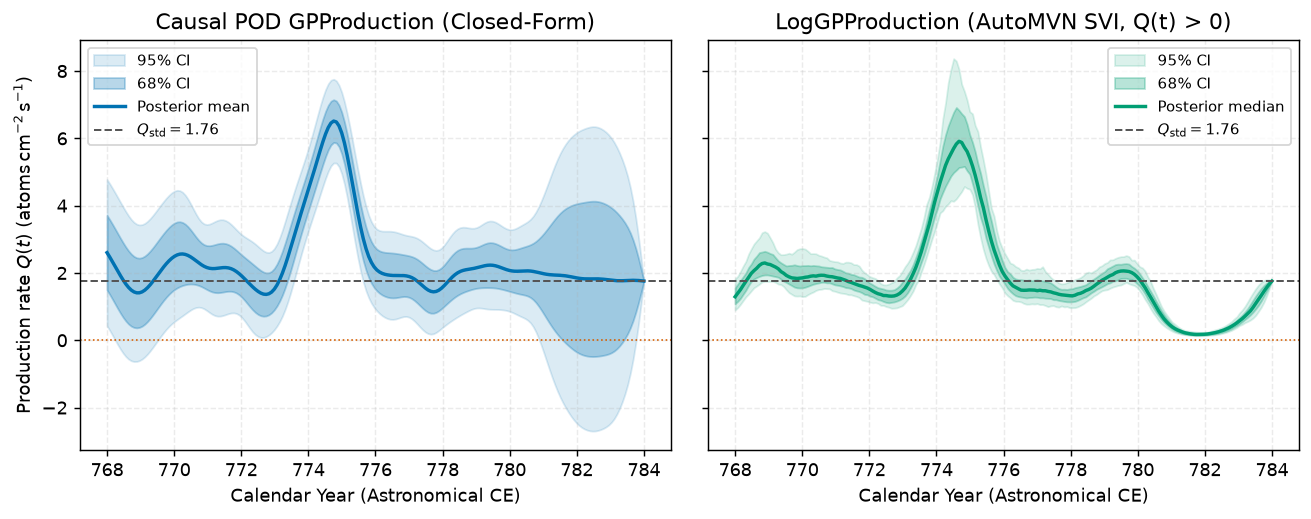

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.1), sharey=True)
tt.plot_production_posterior(t_fine, lp_gp.q_fine_mean, std=lp_gp.q_fine_std, q_std=tt.DEFAULT_Q_STD, ax=axes[0], title="Causal POD GPProduction (Closed-Form)")
tt.plot_production_posterior(t_fine, q_loggp_draws, q_std=tt.DEFAULT_Q_STD, color="#009E73", ax=axes[1], title="LogGPProduction (AutoMVN SVI, Q(t) > 0)")
for ax in axes:
    ax.axhline(0.0, color="#D55E00", lw=0.9, ls=":")
axes[1].set_ylabel("")
fig.tight_layout()
plt.show()


Finally, we plot the posterior-mean `LogGPProduction` Northern and Southern Hemisphere $\Delta^{14}\mathrm{C}(t)$ curves and standardized ring pulls across the `775CE` compilation, confirming a clean fit without parametric pulse assumptions.

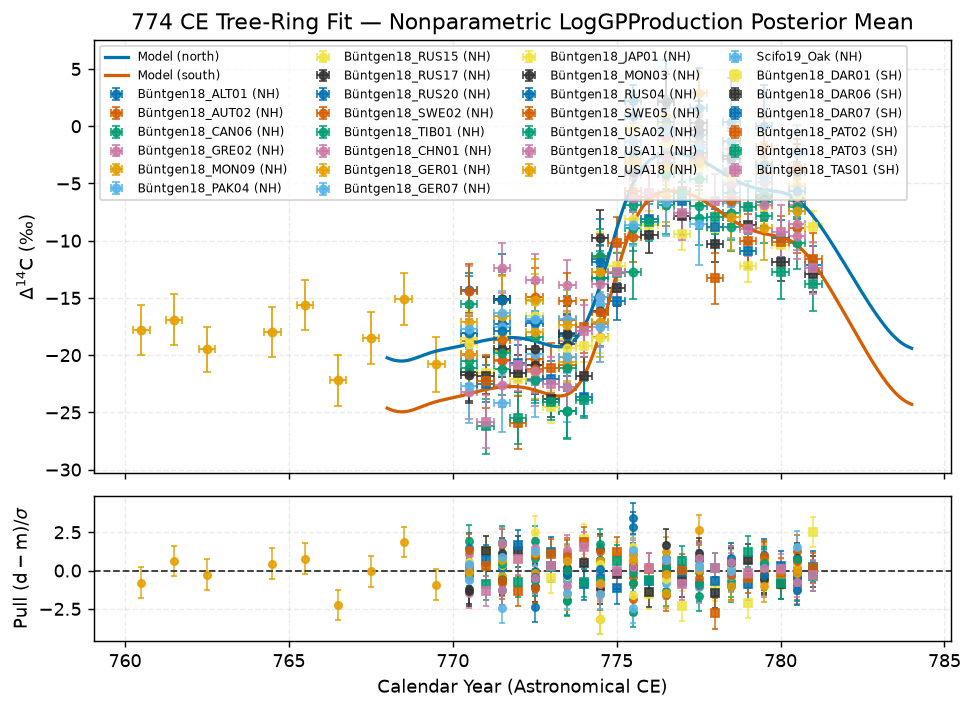

In [5]:
lp_loggp_nh = tt.linear_posterior(svi_res.model, dataset, cfg_off, t_fine=t_fine, hemisphere="north")
lp_loggp_sh = tt.linear_posterior(svi_res.model, dataset, cfg_off, t_fine=t_fine, hemisphere="south")
fig, axes = tt.plot_d14c_fit(
    dataset,
    t_fine=t_fine,
    d14c_pred={"north": lp_loggp_nh.d14c_fine_mean, "south": lp_loggp_sh.d14c_fine_mean},
    ring_pred=lp_loggp_nh.ring_pred_mean,
    show_residuals=True,
    title="774 CE Tree-Ring Fit — Nonparametric LogGPProduction Posterior Mean",
)
axes[0].legend(ncol=4, fontsize=6.5, loc="upper left", frameon=True)
plt.show()


Closed-form Solin–Särkkä `GPProduction` marginalization and variational `LogGPProduction` inference give fast, differentiable nonparametric cosmic-ray reconstructions in `ticktack 2.0`, trading exact analytical marginalization against strict positivity $Q(t) > 0$.